# Image Cell Counting

In [1]:
import torch
import gc
assert torch.cuda.is_available(), "GPU not available" #this will give an error if no GPU available 

In [2]:
!pip install roboflow
!pip install ultralytics

In [3]:
from google.colab import userdata
from roboflow import Roboflow
import os
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2
from getpass import getpass
from ultralytics import YOLO
from IPython.display import Image

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
from pathlib import Path
OUT = Path("/content/drive/MyDrive/aug_study")
OUT.mkdir(parents=True, exist_ok=True)
LOG = OUT / "aug_study_log.csv"

In [6]:
# api_key = userdata.get("ROBOFLOW_API_KEY") #for Google colab UI
api_key = getpass("Roboflow API key: ") #for Google colab implementation in VS code 

In [7]:
rf = Roboflow(api_key=api_key) # *---- Add api key to secrect w name ROBOFLOW_API_KEY ----*
project = rf.workspace("pranjal-singh-evqc5").project(
    "cell-counting-zeqo5-raras"  # *-------- Need to change this to specific dir --------*
)

version = project.version(1) #version generated on roboflow universe
dataset = version.download("yolo26") #chose this format for PyTorch compatibality

loading Roboflow workspace...
loading Roboflow project...


In [8]:
print(os.listdir(dataset.location))
assert "data.yaml" in os.listdir(dataset.location), "Incorrect data format, download as yolo"

['data.yaml', 'README.roboflow.txt', 'valid', 'test', 'train']


## No augmentation Baseline

In [9]:
model = YOLO("yolo26n.pt")

In [10]:
DATA = f"{dataset.location}/data.yaml" #data location for training 

In [11]:
results_log = [] #to compare augmentation results 

"""
Check Ultralytics docs for more details on each parameter: https://docs.ultralytics.com/guides/yolo-data-augmentation
"""
off = dict(
    hsv_h = 0, #hue adjustment
    hsv_s = 0, #saturation adjustment
    hsv_v = 0, #brightness adjustment 
    degrees = 0, #rotation
    translate = 0, #traslation
    scale = 0, #image resize
    shear= 0, #image skewing
    perspective=0, #prespective transformation along x & y axis
    flipud= 0, #flip up and down
    fliplr = 0, #flip right and left
    bgr = 0, #swaps im,age from RGB to BGR
    mosaic = 0, #conmbines four train image into one
    mixup = 0, #blends two images
    cutmix = 0, #cuts rectangle from one image and pastes onto anothe
    copy_paste = 0, #copies objects within or between images #determines method used for copy-pate augmentation     
)

fixed = dict( #fixing the lr, batch size, and optimizer so it doen't span all options on auto
    data=DATA, imgsz=640, single_cls=True,
    optimizer="AdamW", lr0=0.001,   # <- replace with what Step 0 showed
    batch=16, workers=8, plots=False,
)

fast = dict(cache="ram", val=False)   # if RAM is tight

screen = dict(epochs=25, fraction=0.5)   # cheap screening schedule
full   = dict(epochs=50, fraction=1.0)   # final schedule


### Baseline training


In [12]:
name = "scr_baseline"
seed = 0
overrides = {} #overrides whatever parameter is in here with the "OFF" value

model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_baseline_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af541b77ed0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [13]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)   # now saved to Google Drive
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 28.8±18.5 MB/s, size: 37.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 636.5it/s 0.2s2s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.1it/s 1.7s0.2ss
                   all        100       5372      0.959      0.969      0.985      0.575
Speed: 1.2ms preprocess, 6.8ms inference, 0.0ms loss, 1.6ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099


## ONLY Color Augmentation

In [14]:
name = "scr_hsv"
seed = 0
overrides = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_hsv_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af6eb4d4510>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [15]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1629.9±508.4 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.4Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.6it/s 1.5s0.2ss
                   all        100       5372       0.96       0.97      0.986      0.587
Speed: 1.1ms preprocess, 4.8ms inference, 0.0ms loss, 1.8ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657


## Flip Left Right

In [16]:
name = "scr_fliplr"
seed = 0
overrides = dict(fliplr=0.5) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_fliplr_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af54074ead0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [17]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1633.4±519.8 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.6Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.3it/s 1.6s0.2ss
                   all        100       5372      0.952       0.96       0.98       0.54
Speed: 1.1ms preprocess, 4.8ms inference, 0.0ms loss, 1.8ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164


## Flip up and down

In [18]:
name = "scr_flipyd"
seed = 0
overrides = dict(flipud=0.5) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0.5, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_flipyd_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af5fe067890>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [19]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1026.5±328.1 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.4Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.3it/s 1.6s0.2ss
                   all        100       5372      0.956      0.958      0.983      0.552
Speed: 1.1ms preprocess, 4.3ms inference, 0.0ms loss, 1.8ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558


## Transtlate

In [20]:
name = "scr_trans"
seed = 0
overrides = dict(translate=0.1) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_trans_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, over

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af541b83770>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [21]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1705.0±431.3 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.7Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.9it/s 1.4s0.2ss
                   all        100       5372      0.958      0.972      0.988      0.601
Speed: 1.1ms preprocess, 4.2ms inference, 0.0ms loss, 1.5ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487


## Scale

In [22]:
name = "scr_scale"
seed = 0
overrides = dict(scale=0.5) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_scale_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, over

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af605f95490>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [23]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1601.8±526.1 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.7Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.9it/s 1.4s0.2ss
                   all        100       5372      0.952       0.97      0.987        0.6
Speed: 1.0ms preprocess, 4.9ms inference, 0.0ms loss, 1.5ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487
5,screen,scr_scale,0,0.987488,0.600364,0.952140,0.970281


## Rotate

In [24]:
name = "scr_rotate"
seed = 0
overrides = dict(degrees=90) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=90, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_rotate_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, ov

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af634f4fb10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [25]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1643.8±418.7 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.7Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.4it/s 1.6s0.2ss
                   all        100       5372      0.949      0.956      0.981      0.548
Speed: 1.0ms preprocess, 4.7ms inference, 0.0ms loss, 1.8ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487
5,screen,scr_scale,0,0.987488,0.600364,0.952140,0.970281
6,screen,scr_rotate,0,0.981121,0.547992,0.948812,0.955770


## Shear and Perspective

In [26]:
name = "scr_skew"
seed = 0
overrides = dict(shear=5, perspective=0.0005) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_skew_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, overl

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af6eb395c50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [27]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1506.7±441.1 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.7Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.7it/s 1.5s0.2ss
                   all        100       5372      0.955      0.972      0.987      0.575
Speed: 0.9ms preprocess, 4.8ms inference, 0.0ms loss, 1.7ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487
5,screen,scr_scale,0,0.987488,0.600364,0.952140,0.970281
6,screen,scr_rotate,0,0.981121,0.547992,0.948812,0.955770
7,screen,scr_skew,0,0.986743,0.575125,0.955256,0.971519


## Mosaic 

In [28]:
name = "scr_mosac"
seed = 0
overrides = dict(mosaic=1.0, close_mosaic=10) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=scr_mosac_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, ov

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af6d91c7070>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [29]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1670.4±521.9 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.7Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.0it/s 1.4s0.2ss
                   all        100       5372      0.961      0.968      0.987      0.597
Speed: 1.0ms preprocess, 4.5ms inference, 0.0ms loss, 1.8ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487
5,screen,scr_scale,0,0.987488,0.600364,0.952140,0.970281
6,screen,scr_rotate,0,0.981121,0.547992,0.948812,0.955770
7,screen,scr_skew,0,0.986743,0.575125,0.955256,0.971519
8,screen,scr_mosac,0,0.987144,0.596651,0.961012,0.968164


## Mixup 

In [30]:
name = "scr_mixup"
seed = 0
overrides = dict(mixup=0.2) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0, data=/content/cell-counting-1/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=0.5, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.2, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=scr_mixup_s0, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, ov

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af6eb229b70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [31]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1647.0±591.2 MB/s, size: 37.4 KB)
val: Scanning /content/cell-counting-1/valid/labels... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 1.4Kit/s 0.1s
val: New cache created: /content/cell-counting-1/valid/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.7it/s 1.5s0.2ss
                   all        100       5372      0.958      0.966      0.984      0.575
Speed: 1.0ms preprocess, 4.8ms inference, 0.0ms loss, 2.1ms postprocess per image


,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487
5,screen,scr_scale,0,0.987488,0.600364,0.952140,0.970281
6,screen,scr_rotate,0,0.981121,0.547992,0.948812,0.955770
7,screen,scr_skew,0,0.986743,0.575125,0.955256,0.971519
8,screen,scr_mosac,0,0.987144,0.596651,0.961012,0.968164
9,screen,scr_mixup,0,0.984226,0.574508,0.957546,0.965676


## Plotting augmentation exploration results 

In [32]:
LOG = "/content/drive/MyDrive/aug_study/aug_study_log.csv"
df = pd.read_csv(LOG)
df

,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487
5,screen,scr_scale,0,0.987488,0.600364,0.952140,0.970281
6,screen,scr_rotate,0,0.981121,0.547992,0.948812,0.955770
7,screen,scr_skew,0,0.986743,0.575125,0.955256,0.971519
8,screen,scr_mosac,0,0.987144,0.596651,0.961012,0.968164
9,screen,scr_mixup,0,0.984226,0.574508,0.957546,0.965676


In [33]:
precision = df["precision"]
recall = df["recall"]

f1_score = 2*(precision * recall)/(precision + recall)

print(f1_score)

0    0.964163
1    0.965043
2    0.956083
3    0.956716
4    0.965014
5    0.961125
6    0.952278
7    0.963319
8    0.964575
9    0.961594
dtype: float64


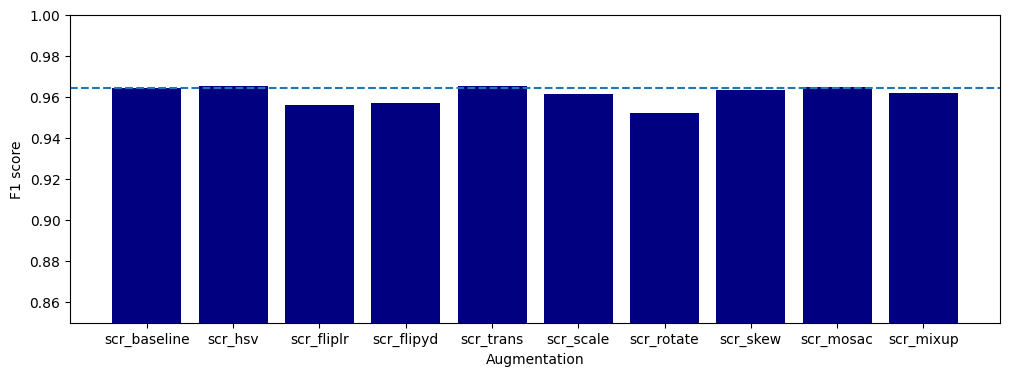

In [34]:
agumen_labels = df["name"]

fig,ax = plt.subplots(figsize=(12,4))
ax.bar(agumen_labels,f1_score, color= "navy")
ax.axhline(y=f1_score[0],linestyle="--")
ax.set_ylim(0.85,1.0)
ax.set_xlabel("Augmentation")
ax.set_ylabel("F1 score")
plt.show()